# Percepción visual y atributos preatentivos

El caso conductor de la unidad es una encuesta de satisfacción de clientes de una cadena de supermercados, con datos de producto, trimestre, satisfacción, ventas y número de clientes. A partir de esta tabla se plantean preguntas analíticas que guían la elección del gráfico y la aplicación de los principios de percepción, claridad y honestidad visual.


## Procesamiento preatentivo de marcas

El procesamiento preatentivo permite que ciertos atributos visuales se perciban de forma inmediata, sin esfuerzo consciente. Las formas, los colores, las posiciones y los movimientos son ejemplos de estos atributos que se captan al instante. Se considera que una tarea es preatentiva cuando puede realizarse en una pantalla con muchos elementos en menos de 200 a 250 milisegundos. Las propiedades preatentivas incluyen el color, la forma, el movimiento y la posición espacial. Al diseñar visualizaciones de datos, conviene emplear estos atributos para dirigir la atención hacia los detalles más importantes. Por ejemplo, un color contrastante resalta una serie o un punto de datos relevante; una forma que evidencie diferencias, como la longitud de barras o el tamaño de burbujas, resulta útil para comparaciones; el movimiento o la animación sirve para mostrar series temporales punto por punto; y la posición espacial permite que los valores atípicos, los conglomerados o las tendencias se detecten con facilidad.

**Ejemplo:** En la encuesta de satisfacción de clientes de la cadena de supermercados, al representar la satisfacción por producto y trimestre, se asigna un color contrastante al producto con menor satisfacción para que se destaque de inmediato entre las demás series. Además, se elige un gráfico de barras para comparar las ventas entre productos, aprovechando que la longitud de las barras se percibe sin esfuerzo.

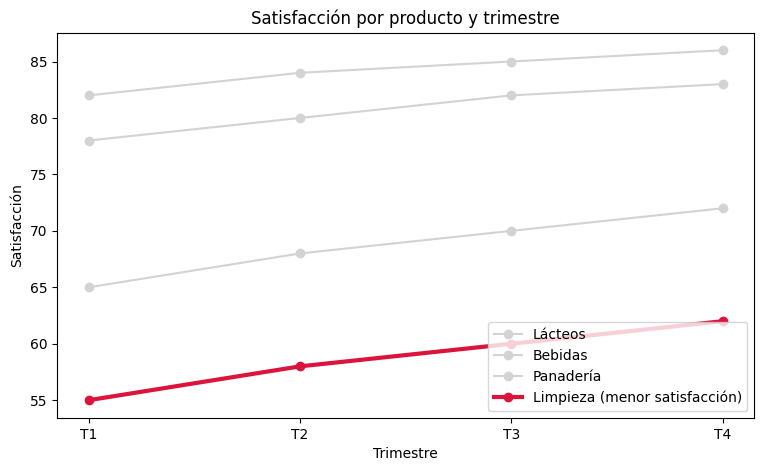

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos ilustrativos de la encuesta de satisfacción por producto y trimestre
datos = {
    'Producto': ['Lácteos', 'Bebidas', 'Panadería', 'Limpieza'],
    'T1': [78, 65, 82, 55],
    'T2': [80, 68, 84, 58],
    'T3': [82, 70, 85, 60],
    'T4': [83, 72, 86, 62]
}
df = pd.DataFrame(datos)

# Identificamos el producto con menor satisfacción promedio
df['Promedio'] = df[['T1', 'T2', 'T3', 'T4']].mean(axis=1)
producto_bajo = df.loc[df['Promedio'].idxmin(), 'Producto']

# Gráfico de líneas: satisfacción por trimestre para cada producto
plt.figure(figsize=(9, 5))
trimestres = ['T1', 'T2', 'T3', 'T4']
for _, fila in df.iterrows():
    # Color contrastante para el producto con menor satisfacción
    if fila['Producto'] == producto_bajo:
        plt.plot(trimestres, fila[trimestres].values, marker='o', linewidth=3,
                 color='crimson', label=fila['Producto'] + ' (menor satisfacción)')
    else:
        plt.plot(trimestres, fila[trimestres].values, marker='o', linewidth=1.5,
                 color='lightgray', label=fila['Producto'])

plt.title('Satisfacción por producto y trimestre')
plt.xlabel('Trimestre')
plt.ylabel('Satisfacción')
plt.legend()
plt.show()

# Gráfico de barras: comparación de ventas entre productos
ventas = {
    'Producto': ['Lácteos', 'Bebidas', 'Panadería', 'Limpieza'],
    'Ventas': [120, 95, 140, 70]
}
df_ventas = pd.DataFrame(ventas)

plt.figure(figsize=(8, 5))
plt.bar(df_ventas['Producto'], df_ventas['Ventas'], color='steelblue')
plt.title('Ventas por producto')
plt.xlabel('Producto')
plt.ylabel('Ventas')
plt.show()

## Atributos visuales y canales

Los atributos visuales, como el color, el tamaño o la intensidad, pueden organizarse para crear una jerarquía visual. Esa jerarquía funciona como un conjunto de instrucciones implícitas para la audiencia, ya que orienta el orden en que conviene procesar la información: primero lo más importante, luego lo que sigue en relevancia. Además, permite enviar al fondo los componentes necesarios pero secundarios, de modo que no compitan por la atención. El resultado es un proceso más fácil y rápido para obtener la información ofrecida. Estos atributos también son útiles para la comunicación efectiva de datos, no solo en texto.

**Ejemplo:** En la encuesta de satisfacción de la cadena de supermercados, al construir un gráfico de barras de satisfacción por producto, se puede destacar con un color más intenso la barra del producto con mayor satisfacción y atenuar las demás, de modo que la audiencia identifique primero ese dato y luego compare el resto.

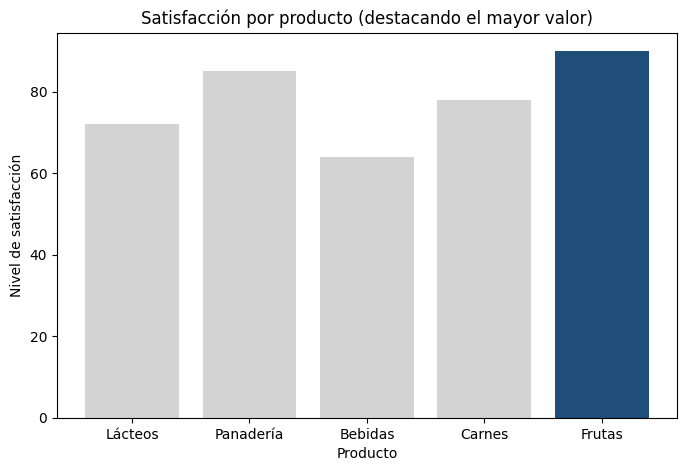

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos ilustrativos de la encuesta de satisfacción por producto
datos = pd.DataFrame({
    'producto': ['Lácteos', 'Panadería', 'Bebidas', 'Carnes', 'Frutas'],
    'satisfaccion': [72, 85, 64, 78, 90]
})

# Identificamos el producto con mayor satisfacción
indice_max = datos['satisfaccion'].idxmax()

# Asignamos un color más intenso a la barra destacada y atenuamos las demás
colores = ['#d3d3d3'] * len(datos)
colores[indice_max] = '#1f4e79'

# Construimos el gráfico de barras
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(datos['producto'], datos['satisfaccion'], color=colores)

# Etiquetas y título que guían la lectura
ax.set_title('Satisfacción por producto (destacando el mayor valor)')
ax.set_xlabel('Producto')
ax.set_ylabel('Nivel de satisfacción')

# Mostramos el gráfico
plt.show()

## Límites del color y codificación redundante

El color no siempre puede transmitir información con la eficacia deseada. Cuando hay muchos elementos por identificar, distinguirlos solo por color resulta difícil, ya que cuesta emparejar los colores del gráfico con los de la leyenda. Incluso si solo se necesitan distinguir dos o tres elementos, el color puede fallar si los elementos coloreados son muy pequeños o si los colores se ven similares para personas con deficiencia en la visión del color. La solución general en todos estos escenarios es usar el color para mejorar la apariencia visual de la figura sin depender por completo de él para transmitir la información clave. Este principio de diseño se denomina codificación redundante, porque propone codificar los datos de forma redundante, utilizando múltiples dimensiones estéticas diferentes.

**Ejemplo:** Al representar la satisfacción promedio por producto y trimestre, se puede usar una escala de color para el nivel de satisfacción y, además, variar la forma del marcador según el trimestre; así, aunque los colores se confundan o los puntos sean pequeños, la información clave sigue siendo identificable por la forma.

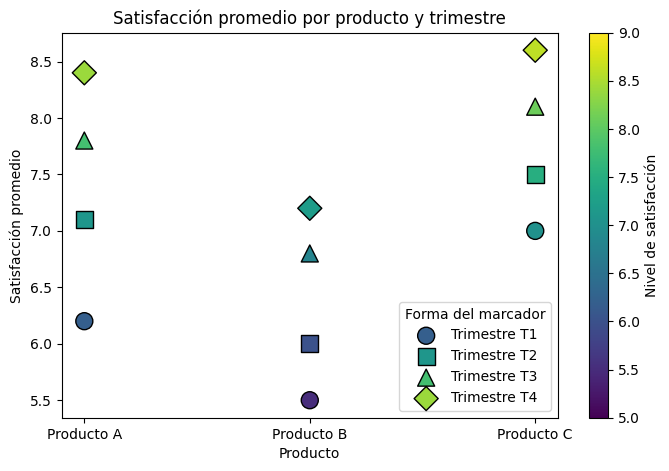

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos ilustrativos: satisfacción promedio por producto y trimestre
datos = {
    'producto': ['Producto A', 'Producto A', 'Producto A', 'Producto A',
                 'Producto B', 'Producto B', 'Producto B', 'Producto B',
                 'Producto C', 'Producto C', 'Producto C', 'Producto C'],
    'trimestre': ['T1', 'T2', 'T3', 'T4'] * 3,
    'satisfaccion': [6.2, 7.1, 7.8, 8.4,
                     5.5, 6.0, 6.8, 7.2,
                     7.0, 7.5, 8.1, 8.6]
}
df = pd.DataFrame(datos)

# Forma del marcador según el trimestre (codificación redundante junto con el color)
marcadores = {'T1': 'o', 'T2': 's', 'T3': '^', 'T4': 'D'}

fig, ax = plt.subplots(figsize=(8, 5))

# Se dibuja cada trimestre con su forma de marcador y color según la satisfacción
for trimestre, grupo in df.groupby('trimestre'):
    ax.scatter(grupo['producto'], grupo['satisfaccion'],
               c=grupo['satisfaccion'], cmap='viridis', vmin=5, vmax=9,
               marker=marcadores[trimestre], s=150,
               label=f'Trimestre {trimestre}', edgecolors='black')

# Etiquetas y título
ax.set_xlabel('Producto')
ax.set_ylabel('Satisfacción promedio')
ax.set_title('Satisfacción promedio por producto y trimestre')

# Barra de color para el nivel de satisfacción
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=5, vmax=9))
sm.set_array([])
fig.colorbar(sm, ax=ax, label='Nivel de satisfacción')

# Leyenda que muestra la forma de cada trimestre
ax.legend(title='Forma del marcador')

plt.show()

**Errores frecuentes:**
- Depender únicamente del color para identificar muchos elementos, lo que dificulta emparejar los colores del gráfico con la leyenda.
- Usar solo color para distinguir pocos elementos cuando son muy pequeños o los colores son similares para personas con deficiencia en la visión del color.

## Práctica

En el gráfico de líneas de satisfacción por trimestre, el color es el único canal que distingue los productos y además todos los colores tienen la misma intensidad, así que no se ve cuál es el producto con menor satisfacción. Corregí el código aplicando dos conceptos: (1) usá codificación redundante, agregando un marcador distinto por producto (por ejemplo 'o', 's', '^') para que la información no dependa solo del color; y (2) creá una jerarquía visual con atributos de color, dibujando la línea del producto con menor satisfacción en un color contrastante y con mayor grosor, y atenuando las demás (color gris claro y menor grosor). Ejecutá y compará el gráfico con el original.


In [ ]:
import matplotlib.pyplot as plt

# Satisfacción promedio por trimestre para tres productos
trimestres = ['T1', 'T2', 'T3', 'T4']
producto_a = [7.2, 7.5, 7.8, 8.0]
producto_b = [6.1, 6.3, 6.0, 6.4]
producto_c = [8.1, 8.3, 8.2, 8.5]

plt.plot(trimestres, producto_a, color='tab:blue', label='Producto A')
plt.plot(trimestres, producto_b, color='tab:orange', label='Producto B')
plt.plot(trimestres, producto_c, color='tab:green', label='Producto C')

# TODO: usá codificación redundante (marcadores distintos por producto) y creá una jerarquía visual: destacá con color contrastante y mayor grosor el producto con menor satisfacción, y atenuá los demás.

plt.xlabel('Trimestre')
plt.ylabel('Satisfacción promedio')
plt.title('Satisfacción por trimestre')
plt.legend()
plt.show()